In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import re
from scipy import stats
import utils
import seaborn as sns
import pingouin as pg
import matplotlib.cm as cm
from matplotlib.patches import Rectangle


import statsmodels.stats.power as smp
from statsmodels.stats.anova import AnovaRM
from tqdm import tqdm


from natsort import index_natsorted

# plt.rcParams['font.family'] = 'Times New Roman'
# plt.rcParams['font.family'] = 'Calibri'

path_figs = "./Figs/"

fingers = ['1', '2', '3', '4', '5'] #mapping of fingers to numbers

iti = 1000 # msecs for inter-trial interval
planTime = 2000 # msecs for precue time
feedbackTime = 2000 # msecs for feedback time

total_sub_num = 20
num_sessions = 4
num_blocks_first_session = 4
num_blocks_second_session = 4
num_blocks_third_session = 4
num_blocks_fourth_session = 4
num_trials_per_block = 120
num_trials_baseline = 20

# without Jaimie and Medha
sub_nums = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15, 16]

utils.set_figure_style("1col")
sns.color_palette('colorblind')



[(0.00392156862745098, 0.45098039215686275, 0.6980392156862745),
 (0.8705882352941177, 0.5607843137254902, 0.0196078431372549),
 (0.00784313725490196, 0.6196078431372549, 0.45098039215686275),
 (0.8352941176470589, 0.3686274509803922, 0.0),
 (0.8, 0.47058823529411764, 0.7372549019607844),
 (0.792156862745098, 0.5686274509803921, 0.3803921568627451),
 (0.984313725490196, 0.6862745098039216, 0.8941176470588236),
 (0.5803921568627451, 0.5803921568627451, 0.5803921568627451),
 (0.9254901960784314, 0.8823529411764706, 0.2),
 (0.33725490196078434, 0.7058823529411765, 0.9137254901960784)]

In [2]:
subjs_list = utils.read_dat_files_subjs_list(sub_nums)

subjs = pd.concat(subjs_list, ignore_index=True)

subjs['TotalTrialNum'] = ((subjs['BN']-1)//2) * (num_trials_per_block + num_trials_baseline) + (subjs['BN']-1)%2 * num_trials_baseline + subjs['TN']
session_edges = np.cumsum([num_blocks_first_session, num_blocks_second_session, num_blocks_third_session, num_blocks_fourth_session])
subjs['day'] = np.searchsorted(session_edges, subjs['BN'], side = 'left') + 1
subjs['chord'] = subjs.apply(utils.extract_chord_form_target_force, axis=1)
subjs['block_type'] = subjs.apply(utils.extract_block_type, axis=1)
subjs['trial_num_within_chord'] = subjs.apply(utils.extract_trial_num_within_chord, axis=1)
subjs['count'] = 1


subjs['num_targets'] = subjs[[f'targetForce{i}' for i in range(1, 6)]].ne(0).sum(axis=1)
subjs.reset_index(drop=True, inplace=True)

In [6]:
import glob
import os
init_time = 2200 # before go cue
end_time = 2925 # after sampling time
def movload(fname):
    # loads .mov files given the path of the file. The .mov files have a specific custom hence the need for a custom function
    with open(fname, 'rb') as fid:
        raw = fid.read()
    if b'\x00' in raw:
        print(f'WARNING: null bytes in {fname}, truncating at first null byte')
        raw = raw[:raw.index(b'\x00')]
    text = raw.decode('utf-8', errors='replace')

    A = []
    num_columns = None
    trial = 0
    skipped = 0
    for line in text.splitlines():
        if not line:
            continue
        if line[0] == 'T':
            a = int(line.split()[1])
            trial += 1
            if a != trial:
                print('Trials out of sequence')
                trial = a
            A.append([])
            num_columns = None
        else:
            lineData = [x for x in line.strip().split('\t') if x != '']
            try:
                values = [float(x) for x in lineData]
            except ValueError:
                skipped += 1
                continue
            if num_columns is None:
                num_columns = len(values)
                A[trial - 1] = np.empty((0, num_columns))
            elif len(values) != num_columns:
                skipped += 1
                continue
            elif values[2] < init_time or values[2] > end_time:
                continue
            a = np.array(values, ndmin=2)
            A[trial - 1] = np.vstack((A[trial - 1], a))

    if skipped:
        print(f'WARNING: skipped {skipped} corrupt line(s) in {fname}')
    return A
pattern = utils.path +  "_*_*.mov"
files = glob.glob(pattern)
dfs = []
for file in files:
    filename = os.path.basename(file)

    parts = filename.split('_')

    if len(parts) >= 5:
        subnum = int(parts[4])
        block_number = int(parts[5].replace('.mov', ''))
        
        if subnum not in sub_nums:
            continue
        print(subnum, block_number)

        trials = movload(file)
        for trial_idx, trial in enumerate(trials):
            df = pd.DataFrame(trial, columns=['state',
                                              'timeReal', 'time',
                                              'ext1', 'ext2', 'ext3', 'ext4', 'ext5', 
                                              'flx1', 'flx2', 'flx3', 'flx4', 'flx5'])
            df['TN'] = trial_idx + 1
            df['BN'] = block_number
            df['subNum'] = subnum
            for finger in fingers:
                df[f'force{finger}'] = np.round(df[f'ext{finger}'] - df[f'flx{finger}'], 2)
            dfs.append(df)
        

dfs = pd.concat(dfs)


subjs_force = dfs.merge(subjs, on = ['subNum' , 'BN', 'TN'], how='inner')[['state', 'time', 'subNum',
                                                                           'BN','TN', 'trialCorr', 'trialErrorType',
                                                                           'targetForce1', 'targetForce2', 'targetForce3', 'targetForce4', 'targetForce5',
                                                                           'endForce1', 'endForce2', 'endForce3', 'endForce4', 'endForce5',
                                                                           'trial_num_within_chord', 'chord', 'block_type', 'num_targets',
                                                                           'TotalTrialNum'] + [f'force{finger}' for finger in fingers]]

8 13
8 7
6 2
6 16
15 8
4 7
10 10
10 4
4 13
10 5
4 12
4 6
10 11
15 9
6 3
8 6
8 12
8 4
8 10
6 15
6 1
4 10
10 7
10 13
4 4
10 12
4 5
4 11
10 6
6 14
8 11
8 5
6 10
6 4
8 1
8 15
10 2
4 15
4 1
3 8
10 16
3 9
10 3
4 14
8 14
6 5
6 11
6 7
6 13
8 16
8 2
10 15
4 2
4 16
10 1
10 14
4 3
8 3
6 12
6 6
16 12
2 5
2 11
16 6
7 9
7 8
2 10
16 7
16 13
2 4
16 5
2 12
2 6
16 11
13 9
13 8
2 7
16 10
16 4
2 13
11 9
16 14
2 3
16 15
2 2
2 16
11 8
16 1
5 9
16 3
2 14
9 9
9 8
16 2
2 15
2 1
5 8
16 16
5 11
11 6
11 12
5 5
13 3
7 14
9 5
9 11
9 10
9 4
7 1
13 16
13 2
7 15
11 13
5 4
5 10
11 7
5 6
11 11
11 5
5 12
13 14
7 3
9 12
9 6
9 7
9 13
7 16
13 1
13 15
7 2
11 4
5 13
5 7
11 10
11 14
5 3
16 9
9 3
7 6
13 11
13 5
7 12
13 4
7 13
7 7
13 10
9 2
9 16
5 16
16 8
11 1
11 15
5 2
11 3
5 14
2 9
9 14
7 11
13 6
13 12
7 5
13 13
7 4
7 10
13 7
9 15
9 1
5 1
2 8
11 16
11 2
5 15
15 1
15 15
3 13
3 7
3 6
3 12
15 14
6 8
15 16
15 2
3 4
3 10
3 11
3 5
15 3
6 9
8 8
15 13
15 7
3 1
4 8
3 15
3 14
4 9
15 6
15 12
8 9
15 4
15 10
3 16
10 8
3 2
3 3
10 9
15 11
15

In [7]:
subjs_force = subjs_force[(subjs_force['time'] >= init_time) & (subjs_force['time'] <= end_time)]

In [8]:
subjs_force_train = utils.finger_melt_Forces(subjs_force)

In [13]:
subjs_force_train.to_csv(utils.path_misc + 'subjs_force_train_force_scaling_analysis.csv', sep = '\t')

# subjs_force_train = pd.read_csv(utils.path_misc + 'subjs_force_train_force_scaling_analysis.csv', sep = '\t')

In [18]:
subjs_force_train.columns

Index(['state', 'time', 'subNum', 'BN', 'TN', 'trial_num_within_chord',
       'chord', 'block_type', 'num_targets', 'targetForce1', 'targetForce2',
       'targetForce3', 'targetForce4', 'targetForce5', 'endForce1',
       'endForce2', 'endForce3', 'endForce4', 'endForce5', 'TotalTrialNum',
       'trialCorr', 'trialErrorType', 'Force_Number', 'Force_Value'],
      dtype='str')

In [14]:
def plot_forces_across_subjects(subjs_forces, chord):
    subjs_forces = subjs_forces[subjs_forces['chord'] == chord].copy()
    forces_correct = utils.remove_error_trials(subjs_forces)
    target_cols = [f"targetForce{finger}" for finger in fingers]
    target_vals = forces_correct[target_cols].iloc[0].to_numpy(dtype=float)

    grouped_forces = forces_correct.groupby(['subNum', 'Force_Number', 'time']).agg({
        'Force_Value': 'median'
    }).reset_index()
    

    # avg_forces = forces_correct.groupby(['Force_Number', 'time'])['Force_Value_Smooth'].mean().reset_index()

    plt.figure(figsize=(3,3))   

    # Map for force number to finger label
    force_label_map = {"force2": "index", "force4": "ring"}
    # Assign distinct colors for force2 and force4 using maximally separated colors in colorblind palette
    colorblind_palette = sns.color_palette('colorblind')
    color_order = {
        "force2": 0,  # blue (palette index 0)
        "force4": 1   # orange (palette index 1)
    }

    for force, data in grouped_forces.groupby('Force_Number'):
        if force not in ['force2', 'force4']:
            continue
        label = force_label_map.get(force, force)
        color_idx = color_order[force]
        sns.lineplot(
            data=data,
            x='time',
            y='Force_Value',
            label=label,
            color=colorblind_palette[color_idx],
            alpha=0.5,
            errorbar='se'
        )
        ax = plt.gca()
        rec_height = 0.5
        finger = force.split('force')[1]
        if target_vals[int(finger)-1] != 0:
            ax.add_patch(Rectangle(
                (2900 - 25, target_vals[int(finger)-1]- (rec_height/2)), 
                50, rec_height, 
                color=colorblind_palette[color_idx],
                alpha=0.5
            ))
    plt.axvline(2400, color = 'black', linestyle = '--', alpha = 0.5) # go cue
    plt.axvline(2900, color = 'black', linestyle = '--', alpha = 0.5) # sampling time

    rec_height = 0.5

    plt.title(f'Chord {chord}')
    plt.ylim(-2.5, 2.5)
    plt.xlabel('Time (ms)')
    plt.ylabel('Force (N)')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    sns.despine(trim = True)
    # plt.savefig(f'{path_figs}subjs_forces/sub{sub_num}_trials_{trial_bin*100}_{(trial_bin+1)*100}_avg_forces.pdf', dpi = 300, bbox_inches='tight')
    # plt.savefig(f'{path_figs}_chord_{chord}_avg_forces.pdf', dpi = 300, bbox_inches='tight')
    plt.show()


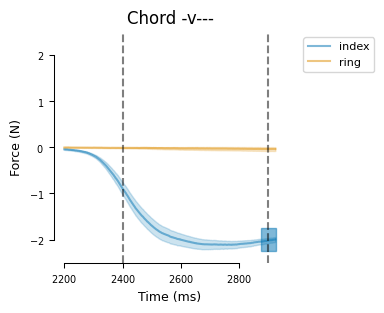

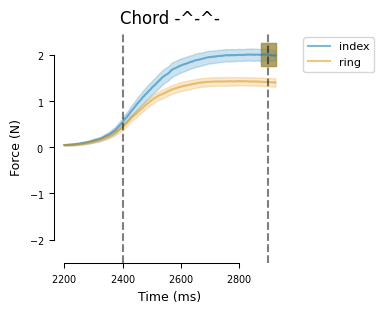

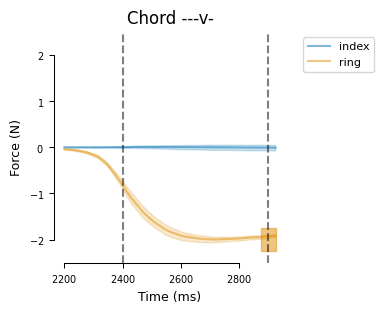

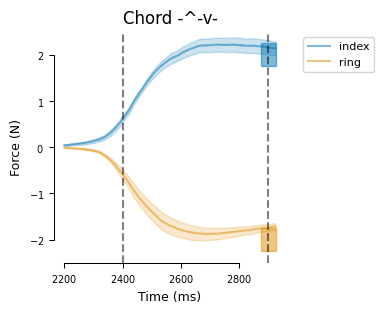

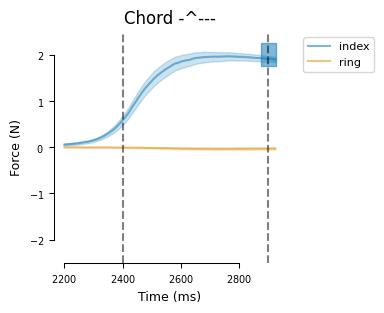

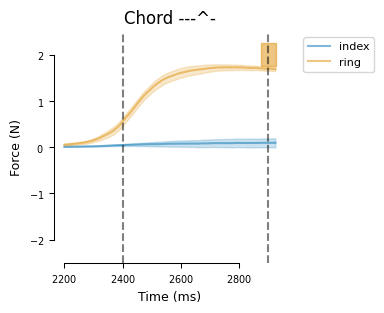

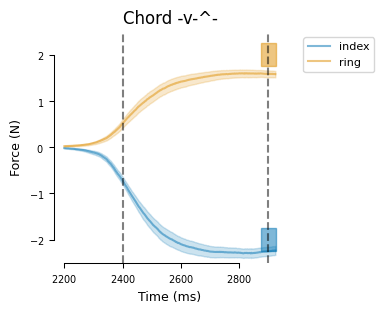

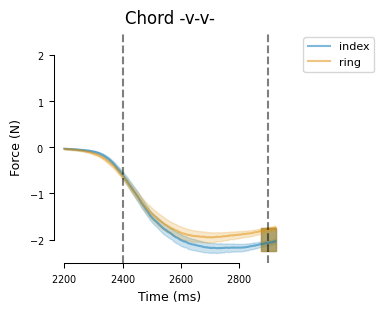

In [15]:
all_chords = subjs_force_train['chord'].unique()
for chord in all_chords:
    plot_forces_across_subjects(subjs_force_train, chord)

In [17]:
def is_flex_ext_or_rest(row):
    chord = row['chord']
    index_action = chord[1]
    ring_action = chord[3]
    # print(chord)
    # print(index_action, ring_action)
    mapping = {
        '^': 'extension',
        'v': 'flexion',
        '-': 'rest',
    }
    index_action = mapping[index_action]
    ring_action = mapping[ring_action]
    return index_action, ring_action

In [18]:
subjs_force_train['index_action'], subjs_force_train['ring_action'] = zip(*subjs_force_train.apply(is_flex_ext_or_rest, axis=1))

In [19]:
def plot_forces_across_fingers(subjs_forces, finger):
    subjs_forces = subjs_forces.copy()

    if finger == 'index':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force2']
        subjs_forces = subjs_forces[subjs_forces['index_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['index_action']
    elif finger == 'ring':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force4']
        subjs_forces = subjs_forces[subjs_forces['ring_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['ring_action']
    else:
        raise ValueError(f"Invalid finger: {finger}")
    forces_correct = utils.remove_error_trials(subjs_forces)

    grouped_forces = forces_correct.groupby(['subNum','action','time']).agg({
        'Force_Value': 'median'
    }).reset_index()

 

    # Map for force number to finger label
    # force_label_map = {"force2": "index", "force4": "ring"}
    # Assign distinct colors for force2 and force4 using maximally separated colors in colorblind palette
    colorblind_palette = sns.color_palette('colorblind')
    color_order = {
        "index": 0,  # blue (palette index 0)
        "ring": 1   # orange (palette index 1)
    }

    for action, data in grouped_forces.groupby('action'):
        plt.figure(figsize=(3,3))  
        color_idx = color_order[finger]
        sns.lineplot(
            data=data,
            x='time',
            y='Force_Value',
            label=action,
            color=colorblind_palette[color_idx],
            alpha=0.5,
            errorbar='se'
        )
        ax = plt.gca()

        plt.axvline(2400, color = 'black', linestyle = '--', alpha = 0.5) # go cue
        plt.axvline(2900, color = 'black', linestyle = '--', alpha = 0.5) # sampling time

        rec_height = 0.5
        if action == 'flexion':
            target_force = -2
        elif action == 'extension':
            target_force = 2
        else:
            target_force = 0
        ax.add_patch(Rectangle(
            (2900 - 25, target_force- (rec_height/2)), 
            50, rec_height, 
            color=colorblind_palette[color_idx],
            alpha=0.5))
        plt.title(f'finger {finger} {action}')
        plt.ylim(-2.5, 2.5)
        plt.xlabel('Time (ms)')
        plt.ylabel('Force (N)')
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        sns.despine(trim = True)
        plt.show()


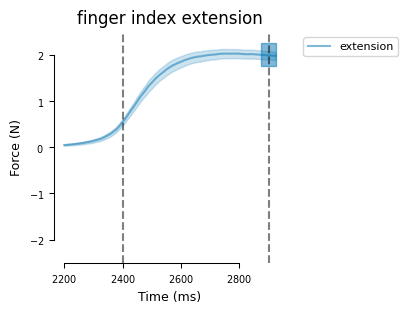

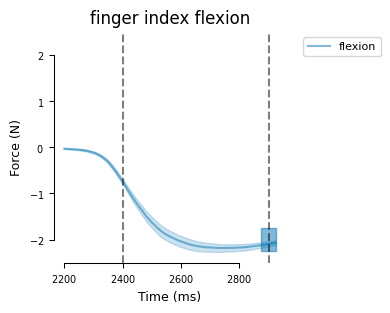

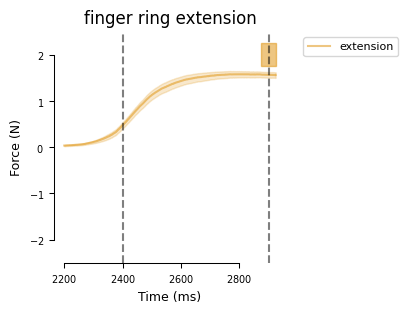

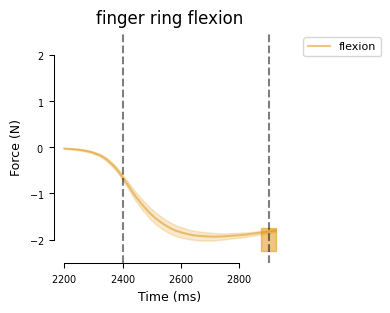

In [20]:
for finger in ['index', 'ring']:
    plot_forces_across_fingers(subjs_force_train, finger)

In [42]:
def plot_derivative_of_forces_across_fingers(subjs_forces, finger):
    subjs_forces = subjs_forces.copy()

    if finger == 'index':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force2']
        subjs_forces = subjs_forces[subjs_forces['index_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['index_action']
    elif finger == 'ring':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force4']
        subjs_forces = subjs_forces[subjs_forces['ring_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['ring_action']
    else:
        raise ValueError(f"Invalid finger: {finger}")
    forces_correct = utils.remove_error_trials(subjs_forces)
    forces_correct = forces_correct.sort_values(by = ['subNum', 'BN', 'TN', 'time'])

    # smooth force within each trial, then differentiate
    forces_correct['Force_Value_smooth'] = (
        forces_correct.groupby(['subNum', 'BN', 'TN'])['Force_Value']
        .transform(lambda x: x.rolling(window=25, center=True, min_periods=1).mean())
    )
    forces_correct['Force_Value_derivative'] = forces_correct.groupby(['subNum', 'BN', 'TN'])['Force_Value_smooth'].diff()
    forces_correct['time_diff'] = forces_correct.groupby(['subNum', 'BN', 'TN'])['time'].diff()
    forces_correct['Force_Value_derivative'] = forces_correct['Force_Value_derivative'] / forces_correct['time_diff']
    grouped_forces = forces_correct.groupby(['subNum','action','time']).agg({
        'Force_Value_derivative': 'median'
    }).reset_index()

    # print(grouped_forces)



 

    # Map for force number to finger label
    # force_label_map = {"force2": "index", "force4": "ring"}
    # Assign distinct colors for force2 and force4 using maximally separated colors in colorblind palette
    colorblind_palette = sns.color_palette('colorblind')
    color_order = {
        "index": 0,  # blue (palette index 0)
        "ring": 1   # orange (palette index 1)
    }

    for action, data in grouped_forces.groupby('action'):
        plt.figure(figsize=(3,3))  
        color_idx = color_order[finger]
        sns.lineplot(
            data=data,
            x='time',
            y='Force_Value_derivative',
            label=action,
            color=colorblind_palette[color_idx],
            alpha=0.5,
            errorbar='se'
        )
        ax = plt.gca()

        plt.axvline(2400, color = 'black', linestyle = '--', alpha = 0.5) # go cue
        plt.axvline(2900, color = 'black', linestyle = '--', alpha = 0.5) # sampling time

        plt.title(f'finger {finger} {action}')
        # plt.ylim(-2.5, 2.5)
        plt.xlabel('Time (ms)')
        plt.ylabel('Force (N)')
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        sns.despine(trim = True)
        plt.show()


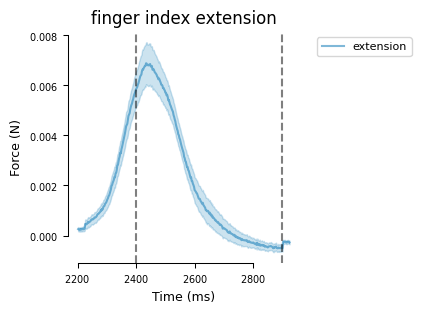

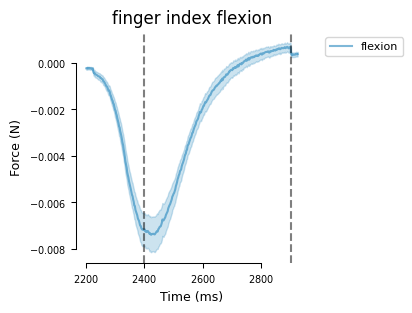

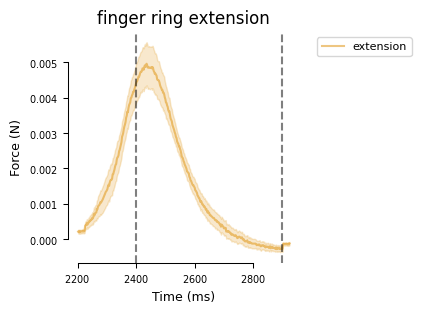

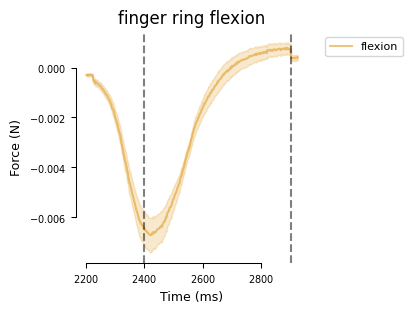

In [43]:
for finger in ['index', 'ring']:
    plot_derivative_of_forces_across_fingers(subjs_force_train, finger)

In [44]:
def plot_forces_across_fingers(subjs_forces, finger):
    subjs_forces = subjs_forces.copy()

    if finger == 'index':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force2']
        subjs_forces = subjs_forces[subjs_forces['index_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['index_action']
        subjs_forces['end_force'] = subjs_forces['endForce2']
    elif finger == 'ring':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force4']
        subjs_forces = subjs_forces[subjs_forces['ring_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['ring_action']
        subjs_forces['end_force'] = subjs_forces['endForce4']
    else:
        raise ValueError(f"Invalid finger: {finger}")
    forces_correct = utils.remove_error_trials(subjs_forces)

    # Map for force number to finger label
    # force_label_map = {"force2": "index", "force4": "ring"}
    # Assign distinct colors for force2 and force4 using maximally separated colors in colorblind palette
    colorblind_palette = sns.color_palette('colorblind')
    color_order = {
        "index": 0,  # blue (palette index 0)
        "ring": 1   # orange (palette index 1)
    }

    for action, data in forces_correct.groupby('action'):

        # divide into three percentiles based on end force
        group_names = ['low', 'medium', 'high']
        data['end_force_percentile'] = pd.qcut(data['end_force'], 3, labels=group_names)

        grouped_forces = data.groupby(['subNum','time', 'end_force_percentile']).agg({
            'Force_Value': 'median'
        }).reset_index()

        plt.figure(figsize=(3,3))  
        color_idx = color_order[finger]
        sns.lineplot(
            data=grouped_forces,
            x='time',
            y='Force_Value',
            # label=action,
            # color=colorblind_palette[color_idx],
            alpha=0.5,
            errorbar='se',
            hue='end_force_percentile'
        )
        ax = plt.gca()

        plt.axvline(2400, color = 'black', linestyle = '--', alpha = 0.5) # go cue
        plt.axvline(2900, color = 'black', linestyle = '--', alpha = 0.5) # sampling time

        rec_height = 0.5
        if action == 'flexion':
            target_force = -2
        elif action == 'extension':
            target_force = 2
        else:
            target_force = 0

        ax.add_patch(Rectangle(
            (2900 - 25, target_force- (rec_height/2)), 
            50, rec_height, 
            color=colorblind_palette[color_idx],
            alpha=0.5))
        plt.title(f'finger {finger} {action}')
        plt.ylim(-3, 3)

        plt.xlabel('Time (ms)')
        plt.ylabel('Force (N)')
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        sns.despine(trim = True)
        plt.show()


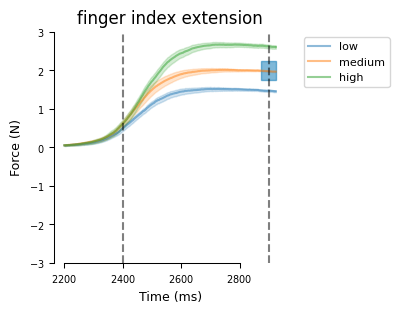

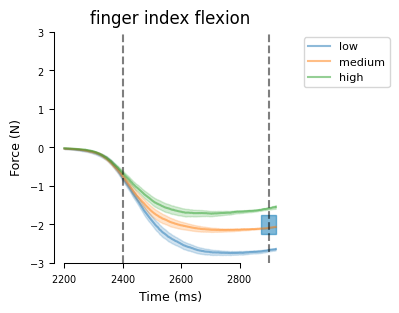

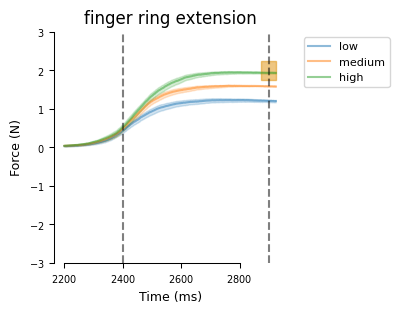

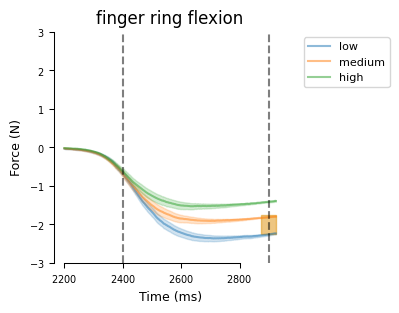

In [45]:
for finger in ['index', 'ring']:
    plot_forces_across_fingers(subjs_force_train, finger)

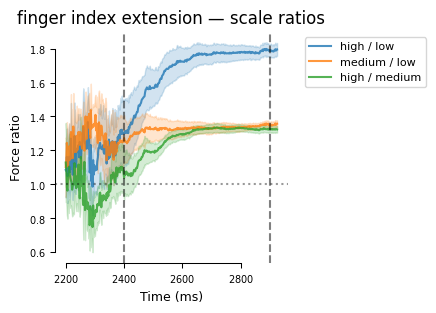

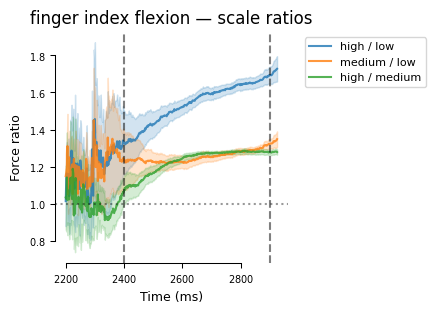

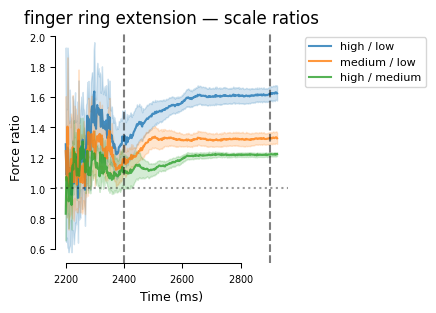

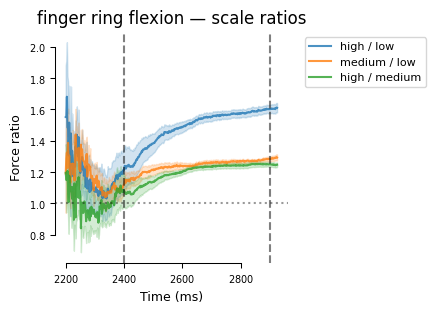

In [46]:
# (duplicate removed — see plot_force_derivative_scale_ratios cell below)
pass


In [47]:
def plot_derivative_of_forces_across_fingers(subjs_forces, finger):
    subjs_forces = subjs_forces.copy()

    if finger == 'index':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force2']
        subjs_forces = subjs_forces[subjs_forces['index_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['index_action']
        subjs_forces['end_force'] = subjs_forces['endForce2']
    elif finger == 'ring':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force4']
        subjs_forces = subjs_forces[subjs_forces['ring_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['ring_action']
        subjs_forces['end_force'] = subjs_forces['endForce4']
    else:
        raise ValueError(f"Invalid finger: {finger}")
    forces_correct = utils.remove_error_trials(subjs_forces)
    forces_correct = forces_correct.sort_values(by = ['subNum', 'BN', 'TN', 'time'])

    # smooth force within each trial, then differentiate
    forces_correct['Force_Value_smooth'] = (
        forces_correct.groupby(['subNum', 'BN', 'TN'])['Force_Value']
        .transform(lambda x: x.rolling(window=25, center=True, min_periods=1).mean())
    )
    forces_correct['Force_Value_derivative'] = forces_correct.groupby(['subNum', 'BN', 'TN'])['Force_Value_smooth'].diff()
    forces_correct['time_diff'] = forces_correct.groupby(['subNum', 'BN', 'TN'])['time'].diff()
    forces_correct['Force_Value_derivative'] = forces_correct['Force_Value_derivative'] / forces_correct['time_diff']


    # Map for force number to finger label
    # force_label_map = {"force2": "index", "force4": "ring"}
    # Assign distinct colors for force2 and force4 using maximally separated colors in colorblind palette
    colorblind_palette = sns.color_palette('colorblind')
    color_order = {
        "index": 0,  # blue (palette index 0)
        "ring": 1   # orange (palette index 1)
    }

    for action, data in forces_correct.groupby('action'):

        # divide into three percentiles based on end force
        group_names = ['low', 'medium', 'high']
        data['end_force_percentile'] = pd.qcut(data['end_force'], 3, labels=group_names)

        grouped_forces = data.groupby(['subNum','time', 'end_force_percentile']).agg({
            'Force_Value_derivative': 'median'
        }).reset_index()

        plt.figure(figsize=(3,3))  
        color_idx = color_order[finger]
        sns.lineplot(
            data=grouped_forces,
            x='time',
            y='Force_Value_derivative',
            # label=action,
            # color=colorblind_palette[color_idx],
            alpha=0.5,
            errorbar='se',
            hue='end_force_percentile'
        )
        ax = plt.gca()

        plt.axvline(2400, color = 'black', linestyle = '--', alpha = 0.5) # go cue
        plt.axvline(2900, color = 'black', linestyle = '--', alpha = 0.5) # sampling time

        # rec_height = 0.5
        # if action == 'flexion':
        #     target_force = -2
        # elif action == 'extension':
        #     target_force = 2
        # else:
        #     target_force = 0

        # ax.add_patch(Rectangle(
        #     (2900 - 25, target_force- (rec_height/2)), 
        #     50, rec_height, 
        #     color=colorblind_palette[color_idx],
        #     alpha=0.5))
        # plt.title(f'finger {finger} {action}')
        # plt.ylim(-3, 3)

        plt.xlabel('Time (ms)')
        plt.ylabel('Force (N)')
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        sns.despine(trim = True)
        plt.show()


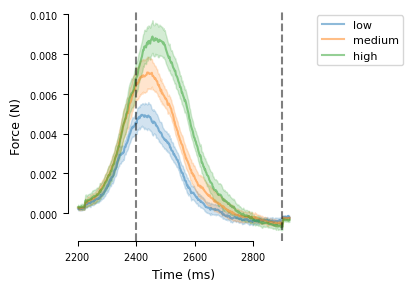

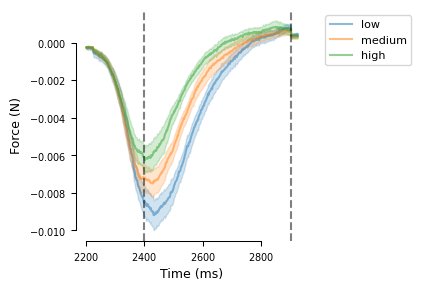

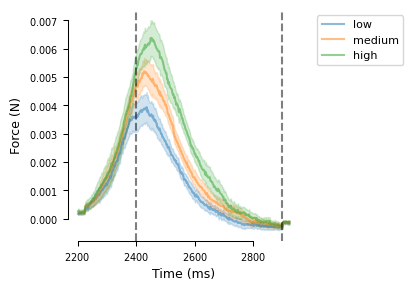

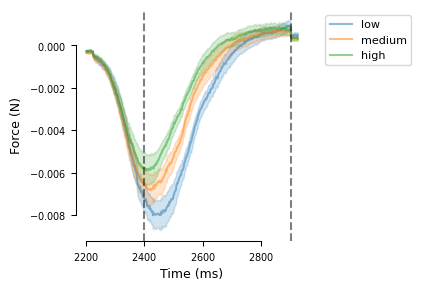

In [49]:
for finger in ['index', 'ring']:
    plot_derivative_of_forces_across_fingers(subjs_force_train, finger)

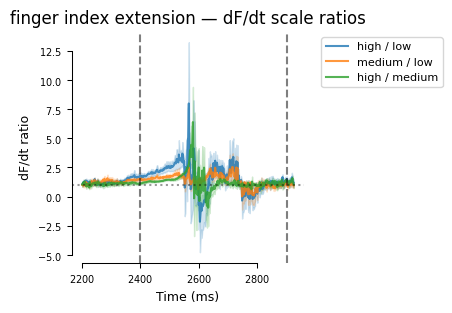

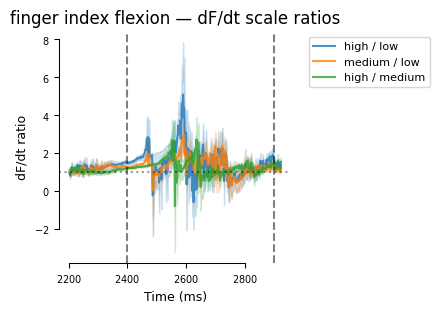

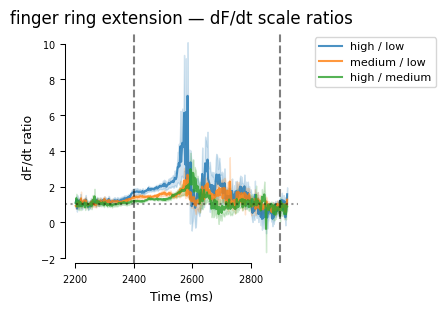

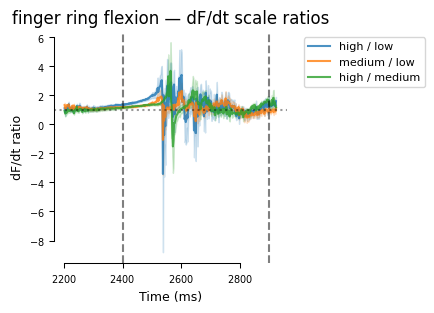

In [51]:
def plot_force_derivative_scale_ratios(subjs_forces, finger, denom_eps=1e-4, rolling_window=25):
    """Plot high/low, medium/low, high/medium dF/dt ratios over time.

    If trajectories are pure scaled versions of each other, each ratio is
    approximately constant across time (flat line).
    """
    subjs_forces = subjs_forces.copy()

    if finger == 'index':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force2']
        subjs_forces = subjs_forces[subjs_forces['index_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['index_action']
        subjs_forces['end_force'] = subjs_forces['endForce2']
    elif finger == 'ring':
        subjs_forces = subjs_forces[subjs_forces['Force_Number'] == 'force4']
        subjs_forces = subjs_forces[subjs_forces['ring_action'] != 'rest']
        subjs_forces['action'] = subjs_forces['ring_action']
        subjs_forces['end_force'] = subjs_forces['endForce4']
    else:
        raise ValueError(f"Invalid finger: {finger}")

    forces_correct = utils.remove_error_trials(subjs_forces)
    forces_correct = forces_correct.sort_values(by=['subNum', 'BN', 'TN', 'time'])

    # smooth force within each trial, then differentiate
    forces_correct['Force_Value_smooth'] = (
        forces_correct.groupby(['subNum', 'BN', 'TN'])['Force_Value']
        .transform(lambda x: x.rolling(window=rolling_window, center=True, min_periods=1).mean())
    )
    forces_correct['Force_Value_derivative'] = forces_correct.groupby(['subNum', 'BN', 'TN'])['Force_Value_smooth'].diff()
    forces_correct['time_diff'] = forces_correct.groupby(['subNum', 'BN', 'TN'])['time'].diff()
    forces_correct['Force_Value_derivative'] = (
        forces_correct['Force_Value_derivative'] / forces_correct['time_diff']
    )

    group_names = ['low', 'medium', 'high']
    ratio_specs = [
        ('high', 'low', 'high / low'),
        ('medium', 'low', 'medium / low'),
        ('high', 'medium', 'high / medium'),
    ]

    for action, data in forces_correct.groupby('action'):
        data = data.copy()
        # qcut ranks signed end_force. For flexion more-negative is stronger,
        # so reverse labels: high = strongest production (still signed force).
        if action == 'flexion':
            labels = ['high', 'medium', 'low']
        else:
            labels = group_names
        data['end_force_percentile'] = pd.qcut(data['end_force'], 3, labels=labels)

        grouped_forces = data.groupby(
            ['subNum', 'time', 'end_force_percentile']
        ).agg({'Force_Value_derivative': 'median'}).reset_index()

        pivoted = grouped_forces.pivot_table(
            index=['subNum', 'time'],
            columns='end_force_percentile',
            values='Force_Value_derivative'
        ).reset_index()

        ratio_frames = []
        for num, den, label in ratio_specs:
            # signed dF/dt / signed dF/dt (no abs)
            ratio = pivoted[num] / pivoted[den]
            ratio = ratio.where(pivoted[den].abs() > denom_eps)
            tmp = pivoted[['subNum', 'time']].copy()
            tmp['ratio'] = ratio
            tmp['comparison'] = label
            ratio_frames.append(tmp)

        ratios = pd.concat(ratio_frames, ignore_index=True)

        plt.figure(figsize=(3, 3))
        sns.lineplot(
            data=ratios,
            x='time',
            y='ratio',
            hue='comparison',
            alpha=0.8,
            errorbar='se',
        )
        plt.axhline(1.0, color='black', linestyle=':', alpha=0.4)
        plt.axvline(2400, color='black', linestyle='--', alpha=0.5)  # go cue
        plt.axvline(2900, color='black', linestyle='--', alpha=0.5)  # sampling time
        plt.title(f'finger {finger} {action} — dF/dt scale ratios')
        plt.xlabel('Time (ms)')
        plt.ylabel('dF/dt ratio')
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='')
        sns.despine(trim=True)
        plt.show()


for finger in ['index', 'ring']:
    plot_force_derivative_scale_ratios(subjs_force_train, finger)
